In [2]:
import pandas as pd

In [3]:
#importing my data and reading it using pandas

df = pd.read_csv(r"C:\Users\Mr.Top\Downloads\Capstone Project\nigerian_retail_and_ecommerce_customer_segmentation_data.csv")

df

,customer_id,segment,avg_order_value_ngn,purchase_frequency,total_orders,total_spend_ngn,last_purchase_days_ago,churn_risk,lifetime_value_ngn,preferred_category,seasonal_buyer
0,CUST822847,mid_tier,152200.92,medium,77,115658.71,141,low,1731792.76,Fashion,False
1,CUST928064,mid_tier,136582.83,medium,69,180661.70,143,medium,261129.27,Health,True
2,CUST221451,high_value,388564.36,medium,51,276543.46,51,low,2537201.91,Home & Living,False
3,CUST986193,premium,4344955.62,high,69,3746437.97,167,medium,4180414.32,Books & Media,True
4,CUST422305,high_value,385518.17,medium,21,393956.62,35,low,4656929.32,Health,True
...,...,...,...,...,...,...,...,...,...,...,...
149995,CUST322735,high_value,311837.05,medium,78,330034.49,142,low,199993.10,Fashion,True
149996,CUST415491,mid_tier,108872.81,medium,6,162833.66,134,low,4538967.34,Baby & Kids,False
149997,CUST716767,mid_tier,87869.99,medium,91,124957.47,240,high,3356665.50,Books & Media,False
149998,CUST306740,budget,37286.22,low,27,45403.50,86,medium,2080698.72,Baby & Kids,False


In [3]:
#checking only first five rows 

df.head()

,customer_id,segment,avg_order_value_ngn,purchase_frequency,total_orders,total_spend_ngn,last_purchase_days_ago,churn_risk,lifetime_value_ngn,preferred_category,seasonal_buyer
0,CUST822847,mid_tier,152200.92,medium,77,115658.71,141,low,1731792.76,Fashion,False
1,CUST928064,mid_tier,136582.83,medium,69,180661.70,143,medium,261129.27,Health,True
2,CUST221451,high_value,388564.36,medium,51,276543.46,51,low,2537201.91,Home & Living,False
3,CUST986193,premium,4344955.62,high,69,3746437.97,167,medium,4180414.32,Books & Media,True
4,CUST422305,high_value,385518.17,medium,21,393956.62,35,low,4656929.32,Health,True


In [4]:
#checking the number of rows and columns we have

print("Row:",df.shape[0])
print('Colums:',df.shape[1])

Row: 150000
Colums: 11


In [5]:
#checking the data type

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   customer_id             150000 non-null  object 
 1   segment                 150000 non-null  object 
 2   avg_order_value_ngn     150000 non-null  float64
 3   purchase_frequency      150000 non-null  object 
 4   total_orders            150000 non-null  int64  
 5   total_spend_ngn         150000 non-null  float64
 6   last_purchase_days_ago  150000 non-null  int64  
 7   churn_risk              150000 non-null  object 
 8   lifetime_value_ngn      150000 non-null  float64
 9   preferred_category      150000 non-null  object 
 10  seasonal_buyer          150000 non-null  bool   
dtypes: bool(1), float64(3), int64(2), object(5)
memory usage: 11.6+ MB


In [6]:
#checking which columns is null or blank

df.isnull().sum()

customer_id               0
segment                   0
avg_order_value_ngn       0
purchase_frequency        0
total_orders              0
total_spend_ngn           0
last_purchase_days_ago    0
churn_risk                0
lifetime_value_ngn        0
preferred_category        0
seasonal_buyer            0
dtype: int64

# investigating the repeated customer_i'd

In [7]:
#count how many times each customer_i'd appears

customer_counts = df['customer_id'].value_counts()

customer_counts

customer_id
CUST978900    5
CUST384389    5
CUST112881    5
CUST367856    4
CUST431402    4
             ..
CUST737438    1
CUST343900    1
CUST650457    1
CUST505476    1
CUST995582    1
Name: count, Length: 138034, dtype: int64

In [8]:
# Show Ids that apear more than once only 

duplicate_customer= customer_counts[customer_counts > 1]

print ("Customer i'd that apears more than once:",len(duplicate_customer))
print ("\nTop repeated customer IDs:")
print(duplicate_customer.head(10))


Customer i'd that apears more than once: 11284

Top repeated customer IDs:
customer_id
CUST978900    5
CUST384389    5
CUST112881    5
CUST367856    4
CUST431402    4
CUST508769    4
CUST135288    4
CUST677046    4
CUST587337    4
CUST192432    4
Name: count, dtype: int64


# checking how many records were affected

In [9]:
#total number of recrds belonging to  customers with repeated IDs

repeated_records = customer_counts[customer_counts > 1].sum()

print("Record belonging to customer_ids:",repeated_records)

Record belonging to customer_ids: 23250


In [10]:
sample_id = duplicate_customer.index[0]

df[df['customer_id'] == sample_id]

,customer_id,segment,avg_order_value_ngn,purchase_frequency,total_orders,total_spend_ngn,last_purchase_days_ago,churn_risk,lifetime_value_ngn,preferred_category,seasonal_buyer
35898,CUST978900,occasional,8263.25,very_low,46,1058.56,266,low,2810126.53,Groceries,False
96917,CUST978900,high_value,348142.87,medium,32,296648.30,14,medium,2052581.42,Groceries,False
123119,CUST978900,mid_tier,135212.14,medium,22,56338.77,131,high,4534579.53,Books & Media,True
128725,CUST978900,high_value,489440.00,medium,49,359215.06,220,low,2341559.82,Health,False
135207,CUST978900,mid_tier,152488.18,medium,98,194013.15,121,low,4732196.74,Electronics,True


# After investigating , i discover that this dataset contains 150,000 records but only 138,036 distinct customers IDs , with some IDs appearing multiple time alongside different customer attributes. Therefore , records were retained as individual observations rather than arbitrarily merging conflicting customer profiles 

In [11]:
#checking for numerical variable 

df[['avg_order_value_ngn','total_orders','total_spend_ngn','last_purchase_days_ago','lifetime_value_ngn']].describe()

,avg_order_value_ngn,total_orders,total_spend_ngn,last_purchase_days_ago,lifetime_value_ngn
count,1.500000e+05,150000.000000,1.500000e+05,150000.000000,1.500000e+05
mean,4.023700e+05,50.524267,4.029449e+05,182.765813,2.506594e+06
std,8.912618e+05,28.931225,8.914190e+05,105.406089,1.439000e+06
min,1.000320e+03,1.000000,1.000770e+03,1.000000,1.000376e+04
25%,4.196790e+04,25.000000,4.207008e+04,92.000000,1.260718e+06
50%,1.248351e+05,50.000000,1.248436e+05,182.000000,2.508156e+06
75%,2.753824e+05,76.000000,2.741794e+05,274.000000,3.745314e+06
max,4.999992e+06,100.000000,4.999947e+06,365.000000,4.999991e+06


In [12]:
#in a norway full number 

pd.set_option ('display.float_format','{:,.2f}'.format)

df[['avg_order_value_ngn','total_orders','total_spend_ngn','last_purchase_days_ago','lifetime_value_ngn']].describe()

,avg_order_value_ngn,total_orders,total_spend_ngn,last_purchase_days_ago,lifetime_value_ngn
count,"150,000.00","150,000.00","150,000.00","150,000.00","150,000.00"
mean,"402,370.05",50.52,"402,944.91",182.77,"2,506,593.63"
std,"891,261.77",28.93,"891,419.01",105.41,"1,439,000.13"
min,"1,000.32",1.00,"1,000.77",1.00,"10,003.76"
25%,"41,967.90",25.00,"42,070.08",92.00,"1,260,718.42"
50%,"124,835.11",50.00,"124,843.57",182.00,"2,508,156.46"
75%,"275,382.38",76.00,"274,179.42",274.00,"3,745,313.88"
max,"4,999,991.68",100.00,"4,999,946.79",365.00,"4,999,990.71"


# Analyze customer behaviour categories

In [13]:
#purchase frequency 

purchase_freq = df["purchase_frequency"].value_counts()

purchase_freq 

purchase_frequency
medium      90099
low         37406
high        14992
very_low     7503
Name: count, dtype: int64

In [14]:
#purchase frequency in percentage

print("percentage of purchase_frequency:\n")
print((df["purchase_frequency"].value_counts(normalize = True)*100).round(2))

percentage of purchase_frequency:

purchase_frequency
medium     60.07
low        24.94
high        9.99
very_low    5.00
Name: proportion, dtype: float64


In [15]:
# Churn risk

churn = df['churn_risk'].value_counts()

print(churn)
print("\nchurn percentage\n")
print((df['churn_risk'].value_counts(normalize =True)*100).round(2))

churn_risk
low       89646
medium    45299
high      15055
Name: count, dtype: int64

churn percentage

churn_risk
low      59.76
medium   30.20
high     10.04
Name: proportion, dtype: float64


In [16]:
#prefered product category

product_category = df['preferred_category'].value_counts()

print (product_category)

print ("percentage\n")

print((df['preferred_category'].value_counts(normalize = True)*100).round(2))

preferred_category
Baby & Kids               15096
Beauty & Personal Care    15045
Books & Media             15040
Home & Living             15015
Fashion                   15003
Sports & Outdoors         14973
Groceries                 14970
Electronics               14964
Automotive                14960
Health                    14934
Name: count, dtype: int64
percentage

preferred_category
Baby & Kids              10.06
Beauty & Personal Care   10.03
Books & Media            10.03
Home & Living            10.01
Fashion                  10.00
Sports & Outdoors         9.98
Groceries                 9.98
Electronics               9.98
Automotive                9.97
Health                    9.96
Name: proportion, dtype: float64


In [17]:
#Seasonal Buyer

Seasonal = df['seasonal_buyer'].value_counts()

print(Seasonal)
print('\nPercentage\n')
print((df['seasonal_buyer'].value_counts(normalize = True)*100).round(2))

seasonal_buyer
False    90026
True     59974
Name: count, dtype: int64

Percentage

seasonal_buyer
False   60.02
True    39.98
Name: proportion, dtype: float64


# Examine relationship between spending,purchase behaviour, and churn risk 

In [18]:
#Does spending differ by purchase frequency ?

df.groupby('purchase_frequency')['total_spend_ngn'].agg(['count','sum','mean','median']).round(2)

,count,sum,mean,median
purchase_frequency,,,,
high,14992,"41,267,069,825.86","2,752,606.04","2,750,225.36"
low,37406,"1,126,092,255.69","30,104.59","30,105.68"
medium,90099,"18,007,368,602.81","199,862.03","162,213.63"
very_low,7503,"41,205,137.45","5,491.82","5,468.23"


In [19]:
# Spending vs churn risk 

df.groupby('churn_risk')['total_spend_ngn'].agg(['count','sum','mean','median']).round(2)

,count,sum,mean,median
churn_risk,,,,
high,15055,"6,072,310,348.62","403,341.77","125,974.12"
low,89646,"35,946,793,735.03","400,986.03","124,670.28"
medium,45299,"18,422,631,738.16","406,689.59","124,878.66"


In [20]:
#Recency vs churn risk

df.groupby('churn_risk')['last_purchase_days_ago'].agg(['count','sum','mean','median']).round(2)

,count,sum,mean,median
churn_risk,,,,
high,15055,2746217,182.41,183.00
low,89646,16404525,182.99,183.00
medium,45299,8264130,182.44,182.00


In [21]:
# selecting variable wd need for customer segmentation 

segmentation_data = df[['last_purchase_days_ago','total_spend_ngn','total_orders','avg_order_value_ngn','lifetime_value_ngn']].copy()

segmentation_data.head()

,last_purchase_days_ago,total_spend_ngn,total_orders,avg_order_value_ngn,lifetime_value_ngn
0,141,"115,658.71",77,"152,200.92","1,731,792.76"
1,143,"180,661.70",69,"136,582.83","261,129.27"
2,51,"276,543.46",51,"388,564.36","2,537,201.91"
3,167,"3,746,437.97",69,"4,344,955.62","4,180,414.32"
4,35,"393,956.62",21,"385,518.17","4,656,929.32"


In [22]:
#checking for missing values 

segmentation_data.isnull().sum()


last_purchase_days_ago    0
total_spend_ngn           0
total_orders              0
avg_order_value_ngn       0
lifetime_value_ngn        0
dtype: int64

In [23]:
# Standardizing the segmentation variables

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


In [24]:
#transform our segmentation variables to the same scale 

segmentation_scaled = scaler.fit_transform(segmentation_data)

In [25]:
# Display the first 5 standardized rows 

segmentation_scaled[:5]

array([[-0.39623852, -0.32228071,  0.91512966, -0.2806919 , -0.53843181],
       [-0.37726422, -0.24935967,  0.63861089, -0.29821553, -1.56043894],
       [-1.25008198, -0.14179849,  0.01644365, -0.0154901 ,  0.02127059],
       [-0.14957263,  3.75076612,  0.63861089,  4.42361477,  1.16318702],
       [-1.40187637, -0.01008315, -1.02050174, -0.01890795,  1.49433125]])

In [26]:
#finding the appropriate number of segments

from sklearn.cluster import KMeans

inertia = []

for k in range (2,11):
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10 )

    kmeans.fit(segmentation_scaled)
    inertia.append(kmeans.inertia_)

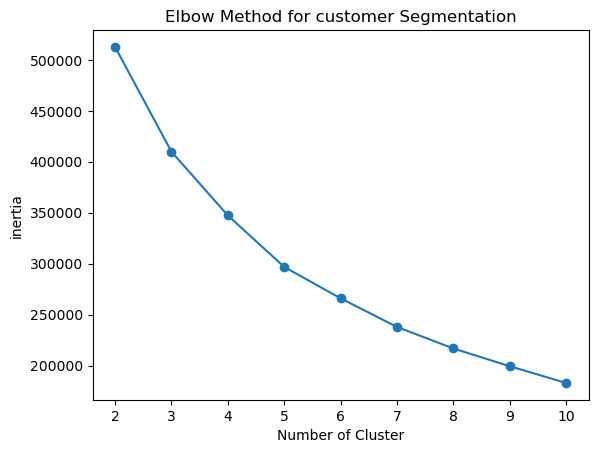

In [27]:
# creating Elbow chart

import matplotlib.pyplot as plt 
plt.plot(range(2,11),inertia, marker ='o')

plt.xlabel('Number of Cluster')
plt.ylabel('inertia')
plt.title('Elbow Method for customer Segmentation')

plt.show()


In [31]:
from sklearn.cluster import KMeans 

k= 4

final_kmeans = KMeans(n_clusters = k , random_state = 42 , n_init = 10 )

df['customer_segment'] = final_kmeans.fit_predict(segmentation_scaled)

print (df['customer_segment'].value_counts().sort_index())

customer_segment
0    42473
1    13049
2    51302
3    43176
Name: count, dtype: int64


In [33]:
segment_profile = df.groupby('customer_segment')[['last_purchase_days_ago','total_spend_ngn','total_orders','avg_order_value_ngn','lifetime_value_ngn']].mean().round(2)

segment_profile

,last_purchase_days_ago,total_spend_ngn,total_orders,avg_order_value_ngn,lifetime_value_ngn
customer_segment,,,,,
0,181.59,"158,890.29",77.16,"157,676.34","3,452,974.76"
1,184.10,"2,969,857.99",50.14,"2,968,213.51","2,519,467.43"
2,180.59,"158,357.90",51.53,"158,859.32","989,169.14"
3,186.10,"157,852.38",23.24,"156,950.64","3,374,744.34"


In [37]:
segment_names = { 0: 'Frequent Buyers', 
                    1: 'High-Value Customers',
                    2: 'Moderate-Value-Buyers',
                    3: 'Low-Frequent Buyers'}
#convert the numerical cluster label into understandable names 
df['customer_segment_names'] = df['customer_segment'].map(segment_names)

#check the number of records in each name segment 

print (df['customer_segment_names'].value_counts())

customer_segment_names
Moderate-Value-Buyers    51302
Low-Frequent Buyers      43176
Frequent Buyers          42473
High-Value Customers     13049
Name: count, dtype: int64


In [42]:
# export dataset with nw customer segments to excel 

df.to_excel (r"C:\Users\Mr.Top\Downloads\Capstone Project\nigerian_retail_and_ecommerce_customer_segmentation_data.xlsx", index = False)

#confirm if the file has been save 

print('Exported successful')

Exported successful
